# DNAscape mapping and simulation tests

This notebook is a hands-on ladder for the two main DNAscape workflows using bundled example data:

- `rmap`: map or fit one replication feature from another under explicit assumptions.
- `rsim`: simulate stochastic DNA replication from a fitted or supplied firing-rate profile.

The examples intentionally start with the same hESC replication-timing data used in the quickstart, then build towards simulation outputs and a small periodic example.

## 0. Setup

Run this notebook from an environment where DNAscape is installed, or start Jupyter from the repository root after an editable install. The figures use DNAscape's own plotting helpers so the style stays close to the quickstart. Rerun the setup cell after editing DNAscape source code to refresh the imported functions.

In [1]:
%reload_ext autoreload
%autoreload 2

from dnascape import *

## 1. Load example timing data

Start with the bundled hESC chromosome 1 replication-timing profile. The raw example data are sampled every 1 kb; we select a genomic interval and, if needed, resample it to a chosen output resolution so the fitting and simulation cells remain fast enough for iterative testing. By default, `select_profile_region` samples the nearest raw value at each output position; `resample_method="linear"` or `resample_method="mean"` can be used when interpolation or averaging is more appropriate.

In [10]:
chr_number = 1
output_resolution_kb = 1
interval_kb = (0, 10_000)
fork_speed = 1.4

replication_timing_full = loadcsv(
    "example",
    example="replication_timing_hESC",
    chr_number=chr_number,
)

replication_timing, positions_kb = select_profile_region(
    replication_timing_full,
    output_resolution_kb=output_resolution_kb,
    interval_kb=interval_kb,
)

len(replication_timing), positions_kb[:5], replication_timing[:5]

(10000,
 array([0., 1., 2., 3., 4.]),
 array([206.04622947, 206.03534491, 206.01348763, 205.98048183,
        205.93606531]))

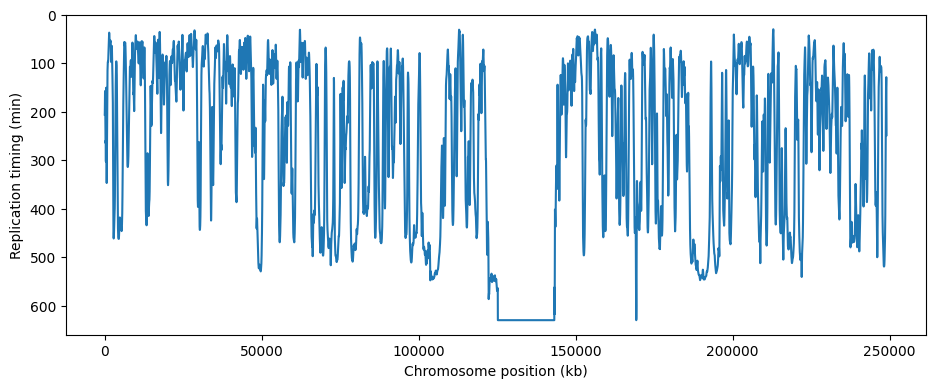

In [9]:
plotf(
    replication_timing,
    x_array=positions_kb,
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
)

## 2. Inspect the mapping vocabulary

`rmap` uses canonical feature labels. Aliases such as `timing`, `rt`, `fr`, `initiation_rate`, `fs`, and `rfd` are normalised internally, but examples should prefer the canonical names.

In [ ]:
rmap.features()

In [ ]:
rmap.describe()

## 3. Fit firing rate from timing

This is the central inverse-mapping example: given replication timing and a fixed fork-speed assumption, infer a space-dependent firing-rate profile.

In [ ]:
fit_assumptions = {
    "fork_speed": fork_speed,
    "resolution": output_resolution_kb,
    "maxiter": 6,
}

firing_fit = rmap(
    source={"replication_timing": replication_timing},
    target="firing_rate",
    assumptions=fit_assumptions,
    return_info=True,
)

firing_rate = firing_fit["values"]
firing_fit["method"], firing_rate.shape

In [ ]:
plotf(
    firing_rate,
    x_array=positions_kb,
    xtitle="Chromosome position (kb)",
    ytitle="Firing rate",
)

## 4. Forward-map the fitted profile

The fitted firing-rate profile can be mapped back to replication timing. This closes the deterministic mapping loop before moving to stochastic simulations.

In [ ]:
timing_from_firing = rmap(
    source={"firing_rate": firing_rate},
    target="replication_timing",
    assumptions=fit_assumptions,
)

plotf(
    replication_timing,
    timing_from_firing,
    x_array=positions_kb,
    labels=["Timing data", "Timing from fitted firing rate"],
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
)

## 5. Map timing to fork directionality

Fork directionality is another feature view of timing. Raw timing data can be noisy after downsampling, so this round-trip check uses the smoother timing profile generated from the fitted firing rate.

In [ ]:
directionality_assumptions = {
    "fork_speed": fork_speed,
    "resolution": output_resolution_kb,
}

timing_reference = timing_from_firing

fork_directionality = rmap(
    source={"replication_timing": timing_reference},
    target="fork_directionality",
    assumptions=directionality_assumptions,
)

timing_from_directionality = rmap(
    source={"fork_directionality": fork_directionality},
    target="replication_timing",
    assumptions={**directionality_assumptions, "T0": timing_reference[0]},
)

plotf(
    fork_directionality,
    x_array=positions_kb,
    xtitle="Chromosome position (kb)",
    ytitle="Fork directionality",
    ylims=(-1.05, 1.05),
)

In [ ]:
plotf(
    timing_reference,
    timing_from_directionality,
    x_array=positions_kb,
    labels=["Timing from fitted firing rate", "Round-trip through fork directionality"],
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
)

## 6. Simulate from the fitted firing rate

`rsim` is the generative side of DNAscape. Here we simulate replication from the fitted firing-rate profile, using the same fork speed and genomic resolution.

In [ ]:
simulation = rsim(
    firing_rate=firing_rate,
    fork_speed=fork_speed,
    sim_number=1000,
    resolution=output_resolution_kb,
    seed=1,
    time_statsQ=True,
)

sorted(simulation.keys())

In [ ]:
plotf(
    replication_timing,
    timing_from_firing,
    simulation["replication_timing"],
    x_array=positions_kb,
    labels=["Timing data", "Deterministic map", "Mean simulation"],
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
)

## 7. Quickstart-style simulation outputs

The quickstart also checks time courses, origin efficiency, inter-origin distances, and the number of origins. This section keeps the same spirit while using the new naming and mapping structure. Because this notebook can downsample the input profile, inter-origin distances are quantised by `output_resolution_kb`; the plot should have the same interpretation as the quickstart, but not necessarily the same shape.

In [ ]:
plotf(
    simulation["replicated_fraction"],
    simulation["active_forks"],
    labels=["Replicated fraction", "Active forks"],
    dual_axis=True,
    xtitle="Time (min)",
)

In [ ]:
plotf(
    simulation["origin_efficiency"],
    firing_rate,
    x_array=positions_kb,
    labels=["Origin efficiency", "Firing rate"],
    dual_axis=True,
    xtitle="Chromosome position (kb)",
)

In [ ]:
ploth(
    simulation["inter_origin_distance"],
    xtitle="Inter-origin distance (kb)",
    bin_size=output_resolution_kb,
    xmax=1000,
)

In [ ]:
summary = {
    "mean_completion_time": sum(simulation["completion_time"]) / len(simulation["completion_time"]),
    "mean_num_origins": sum(simulation["num_origins"]) / len(simulation["num_origins"]),
    "mean_origin_efficiency": sum(simulation["origin_efficiency"]) / len(simulation["origin_efficiency"]),
}

summary

## 8. Compare with bundled firing-rate data

The quickstart also includes a bundled hESC firing-rate example. Loading it here gives a useful reference profile for checking whether the fitted profile is in the same broad spatial regime.

In [ ]:
firing_rate_reference_full = loadcsv(
    "example",
    example="firing_rate_hESC",
    chr_number=chr_number,
)

firing_rate_reference, _ = select_profile_region(
    firing_rate_reference_full,
    output_resolution_kb=output_resolution_kb,
    interval_kb=interval_kb,
)

plotf(
    firing_rate,
    firing_rate_reference,
    x_array=positions_kb,
    labels=["rmap fitted firing rate", "Bundled firing-rate example"],
    xtitle="Chromosome position (kb)",
    ytitle="Firing rate",
)

## 9. Periodic example from the quickstart

The plasmid-style timing example is small enough to use directly. It exercises the same mapping and simulation ideas under a periodic geometry assumption.

In [ ]:
plasmid_timing = loadcsv("example", example="replication_timing_Pl", chr_number=1)
plasmid_timing = rescale(plasmid_timing, [0, 60])

plasmid_assumptions = {
    "fork_speed": 0.6,
    "resolution": 5,
    "geometry": "periodic",
    "maxiter": 6,
}

plasmid_firing_rate = rmap(
    source={"replication_timing": plasmid_timing},
    target="firing_rate",
    assumptions=plasmid_assumptions,
)

plotf(
    plasmid_timing,
    invyQ=True,
    resolution=5,
    xtitle="Circular coordinate",
    ytitle="Replication timing (min)",
)

In [ ]:
plotf(
    plasmid_firing_rate,
    resolution=5,
    xtitle="Circular coordinate",
    ytitle="Firing rate",
)

In [ ]:
plasmid_simulation = rsim(
    firing_rate=plasmid_firing_rate,
    fork_speed=0.6,
    sim_number=10,
    resolution=5,
    geometry="periodic",
    stall_rate=0.1,
    seed=2,
    time_statsQ=True,
)

plotf(
    plasmid_timing,
    plasmid_simulation["replication_timing"],
    labels=["Timing data", "Mean simulation"],
    invyQ=True,
    resolution=5,
    xtitle="Circular coordinate",
    ytitle="Replication timing (min)",
)

## 10. Planned mapping routes

Some mapping routes are registered before they are implemented. Keeping them visible makes the intended API explicit without adding failing notebook cells.

In [ ]:
[
    (spec.source, spec.target, spec.method)
    for spec in rmap.routes()
    if not spec.implemented
]

## 11. Extension checklist

Use this notebook as the first smoke test when adding a mapping or simulation feature:

1. Add the route to `rmap` with canonical feature labels.
2. Add a small real-data cell here with explicit assumptions.
3. Plot the mapped or simulated output with `plotf` against the input feature.
4. Promote the example into formal tests once the route stabilises.